<a href="https://colab.research.google.com/github/1234Imesh/EN4554-Convolutional-Neural-Networks/blob/main/EN4554_Assignment_2_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 - Assignment 2: Convolutional Neural Networks

G. A. I. N. M. Abeysinghe  
220009H

Github: https://github.com/1234Imesh/EN4554-Convolutional-Neural-Networks.git

This notebook contains the complete implementation and report for Tasks 1-4. It is written for PyTorch and is compatible with a Google Colab T4 GPU. All random seeds are fixed, CIFAR-10 is split into 45,000 training and 5,000 validation images, normalization statistics are computed from the training split only, and the test set is evaluated exactly once at the end of Task 4.


## Reproducibility and runtime configuration

`FULL_RUN=True` is the assignment run. It performs every experiment on the required data and may take a few hours. Set it to `False` only for a short laptop smoke test; smoke-test numbers are not submission results. The default is deliberately the full assignment configuration.

The code avoids machine-specific paths. CIFAR-10 is downloaded automatically to `./data`. No test-set loader is created until the final evaluation cell.


In [8]:
import os
import random
import time
import copy
import math
from dataclasses import dataclass
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms

SEED = 4554
FULL_RUN = True          # Keep True for the submitted run; False is only a smoke test.
DATA_ROOT = "./data"
NUM_WORKERS = 0 if os.name == "nt" else 2
PIN_MEMORY = torch.cuda.is_available()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything()
print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
if FULL_RUN and DEVICE.type != "cuda":
    print("WARNING: FULL_RUN is intended for a Colab T4 GPU and will be slow on CPU.")


PyTorch: 2.11.0+cpu
Device: cpu


## Dataset preparation

CIFAR-10 has 50,000 training images and 10,000 test images. Each image is a 32x32 RGB image belonging to one of ten classes. A seeded permutation creates the required 45,000/5,000 train/validation split. Channel means and standard deviations are computed **only from the 45,000 training images**, preventing validation or test information from leaking into preprocessing.


In [9]:
raw_train = datasets.CIFAR10(
    root=DATA_ROOT, train=True, download=True, transform=transforms.ToTensor()
)

split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(len(raw_train), generator=split_generator).tolist()
train_indices = permutation[:45_000]
val_indices = permutation[45_000:]


def compute_channel_stats(dataset, indices, batch_size=1024):
    loader = DataLoader(
        Subset(dataset, indices), batch_size=batch_size, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
    )
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_sq_sum = torch.zeros(3, dtype=torch.float64)
    pixel_count = 0
    for images, _ in loader:
        images = images.to(torch.float64)
        channel_sum += images.sum(dim=(0, 2, 3))
        channel_sq_sum += (images ** 2).sum(dim=(0, 2, 3))
        pixel_count += images.shape[0] * images.shape[2] * images.shape[3]
    mean = channel_sum / pixel_count
    std = (channel_sq_sum / pixel_count - mean ** 2).sqrt()
    return mean.float().tolist(), std.float().tolist()


TRAIN_MEAN, TRAIN_STD = compute_channel_stats(raw_train, train_indices)
print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Per-channel mean:", [round(x, 6) for x in TRAIN_MEAN])
print("Per-channel std: ", [round(x, 6) for x in TRAIN_STD])


100%|██████████| 170M/170M [21:21<00:00, 133kB/s]


Training images: 45000
Validation images: 5000
Per-channel mean: [0.491961, 0.482511, 0.446764]
Per-channel std:  [0.247009, 0.243481, 0.261541]


In [10]:
class IndexedCIFAR10(Dataset):
    # Applies a transform after selecting a fixed subset of CIFAR-10.
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        image, target = self.base_dataset[self.indices[item]]
        # raw_train currently returns a tensor; transforms below expect either form.
        if torch.is_tensor(image):
            image = transforms.ToPILImage()(image)
        return self.transform(image), target


eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(TRAIN_MEAN, TRAIN_STD),
])

train_dataset = IndexedCIFAR10(raw_train, train_indices, eval_transform)
val_dataset = IndexedCIFAR10(raw_train, val_indices, eval_transform)


def make_loader(dataset, batch_size=128, shuffle=False, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, generator=generator,
        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
        persistent_workers=(NUM_WORKERS > 0)
    )


train_loader = make_loader(train_dataset, 256, True)
val_loader = make_loader(val_dataset, 256, False)

images, labels = next(iter(train_loader))
print("Batch shape:", tuple(images.shape), "Labels shape:", tuple(labels.shape))
print("Classes:", raw_train.classes)


Batch shape: (256, 3, 32, 32) Labels shape: (256,)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


The printed statistics are properties of this exact seeded training split. Applying the same normalization to all three partitions puts the RGB channels on comparable scales without using validation or test data to choose preprocessing parameters.

---

# Task 1 - Backpropagation

## 1(a) Explicit `Linear`, `ReLU`, and softmax cross-entropy

The following implementation deliberately avoids autograd. Each object caches only the quantities needed by its backward pass. For a mini-batch of size $N$, softmax cross-entropy returns the mean loss, so its logit gradient is $(p-y)/N$.


In [11]:
class ManualLinear:
    def __init__(self, in_features, out_features, generator=None):
        scale = math.sqrt(2.0 / in_features)
        self.weight = torch.randn(
            out_features, in_features, generator=generator, device=DEVICE
        ) * scale
        self.bias = torch.zeros(out_features, device=DEVICE)
        self.grad_weight = torch.zeros_like(self.weight)
        self.grad_bias = torch.zeros_like(self.bias)
        self.input = None

    def forward(self, x):
        self.input = x
        return x @ self.weight.t() + self.bias

    def backward(self, grad_output):
        self.grad_weight.copy_(grad_output.t() @ self.input)
        self.grad_bias.copy_(grad_output.sum(dim=0))
        return grad_output @ self.weight

    def parameters_and_gradients(self):
        return [(self.weight, self.grad_weight), (self.bias, self.grad_bias)]


class ManualReLU:
    def __init__(self):
        self.positive = None

    def forward(self, x):
        self.positive = x > 0
        return x.clamp_min(0)

    def backward(self, grad_output):
        return grad_output * self.positive


class ManualSoftmaxCrossEntropy:
    def __init__(self):
        self.probabilities = None
        self.targets = None

    def forward(self, logits, targets):
        shifted = logits - logits.max(dim=1, keepdim=True).values
        exp_logits = shifted.exp()
        self.probabilities = exp_logits / exp_logits.sum(dim=1, keepdim=True)
        self.targets = targets
        n = logits.shape[0]
        return -torch.log(self.probabilities[torch.arange(n, device=logits.device), targets] + 1e-12).mean()

    def backward(self):
        gradient = self.probabilities.clone()
        gradient[torch.arange(gradient.shape[0], device=gradient.device), self.targets] -= 1
        return gradient / gradient.shape[0]


class ManualMLP:
    def __init__(self, dimensions, seed=SEED):
        generator = torch.Generator(device=DEVICE).manual_seed(seed)
        self.layers = []
        for index in range(len(dimensions) - 2):
            self.layers.extend([
                ManualLinear(dimensions[index], dimensions[index + 1], generator),
                ManualReLU(),
            ])
        self.layers.append(ManualLinear(dimensions[-2], dimensions[-1], generator))
        self.loss_layer = ManualSoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self):
        gradient = self.loss_layer.backward()
        for layer in reversed(self.layers):
            gradient = layer.backward(gradient)

    def parameters_and_gradients(self):
        for layer in self.layers:
            if isinstance(layer, ManualLinear):
                yield from layer.parameters_and_gradients()

    @torch.no_grad()
    def step(self, learning_rate):
        for parameter, gradient in self.parameters_and_gradients():
            parameter -= learning_rate * gradient


## 1(b) Gradient verification

Two independent checks are used. First, the manually computed derivatives are compared with PyTorch autograd. Second, selected entries are compared with centred finite differences,

$$\frac{\partial L}{\partial \theta_i}\approx\frac{L(\theta_i+\epsilon)-L(\theta_i-\epsilon)}{2\epsilon}.$$

Double precision and non-boundary inputs reduce numerical error. Relative error is $\lVert g-\hat g\rVert/(\lVert g\rVert+\lVert\hat g\rVert+10^{-12})$.


In [12]:
def relative_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()


seed_everything()
x_check = torch.randn(5, 7, device=DEVICE, dtype=torch.float64)
y_check = torch.tensor([0, 1, 2, 1, 0], device=DEVICE)

manual = ManualMLP([7, 6, 3])
for layer in manual.layers:
    if isinstance(layer, ManualLinear):
        layer.weight = layer.weight.double()
        layer.bias = layer.bias.double()
        layer.grad_weight = layer.grad_weight.double()
        layer.grad_bias = layer.grad_bias.double()
manual_logits = manual.forward(x_check)
manual_loss = manual.loss_layer.forward(manual_logits, y_check)
manual.backward()

# Rebuild the same computation with autograd using cloned parameters.
linear_layers = [layer for layer in manual.layers if isinstance(layer, ManualLinear)]
w1 = linear_layers[0].weight.detach().clone().requires_grad_(True)
b1 = linear_layers[0].bias.detach().clone().requires_grad_(True)
w2 = linear_layers[1].weight.detach().clone().requires_grad_(True)
b2 = linear_layers[1].bias.detach().clone().requires_grad_(True)
autograd_logits = F.relu(x_check @ w1.t() + b1) @ w2.t() + b2
autograd_loss = F.cross_entropy(autograd_logits, y_check)
autograd_loss.backward()

manual_gradients = [gradient for _, gradient in manual.parameters_and_gradients()]
autograd_gradients = [w1.grad, b1.grad, w2.grad, b2.grad]
names = ["W1", "b1", "W2", "b2"]
rows = []
for name, manual_grad, auto_grad in zip(names, manual_gradients, autograd_gradients):
    rows.append({
        "parameter": name,
        "manual_vs_autograd_relative_error": relative_error(manual_grad, auto_grad),
        "torch_allclose": torch.allclose(manual_grad, auto_grad, rtol=1e-7, atol=1e-9),
    })

# Centred differences for representative entries from every parameter tensor.
epsilon = 1e-6
finite_difference_errors = []
for name, (parameter, analytic_gradient) in zip(names, manual.parameters_and_gradients()):
    flat_parameter = parameter.view(-1)
    flat_gradient = analytic_gradient.view(-1)
    sample_positions = torch.linspace(
        0, flat_parameter.numel() - 1, steps=min(5, flat_parameter.numel())
    ).long().unique()
    numerical_values, analytic_values = [], []
    for position in sample_positions:
        original = flat_parameter[position].item()
        with torch.no_grad():
            flat_parameter[position] = original + epsilon
            loss_plus = manual.loss_layer.forward(manual.forward(x_check), y_check).item()
            flat_parameter[position] = original - epsilon
            loss_minus = manual.loss_layer.forward(manual.forward(x_check), y_check).item()
            flat_parameter[position] = original
        numerical_values.append((loss_plus - loss_minus) / (2 * epsilon))
        analytic_values.append(flat_gradient[position].item())
    numerical = torch.tensor(numerical_values, dtype=torch.float64)
    analytic = torch.tensor(analytic_values, dtype=torch.float64)
    finite_difference_errors.append(relative_error(numerical, analytic))

gradient_check_table = pd.DataFrame(rows)
gradient_check_table["finite_difference_relative_error"] = finite_difference_errors
display(gradient_check_table)

assert gradient_check_table["torch_allclose"].all(), "Manual and autograd gradients do not match."
assert gradient_check_table["finite_difference_relative_error"].max() < 1e-5, "Finite-difference check failed."
print("Interpretation: allclose is true for every tensor and the relative errors are close to numerical precision. "
      "This supports the correctness of both the layer backward passes and the softmax-cross-entropy derivative.")


,parameter,manual_vs_autograd_relative_error,torch_allclose,finite_difference_relative_error
0,W1,1.473450e-16,True,7.581633e-10
1,b1,1.321373e-16,True,3.348305e-10
2,W2,1.225722e-16,True,2.491979e-10
3,b2,4.728826e-17,True,4.025072e-10


Interpretation: allclose is true for every tensor and the relative errors are close to numerical precision. This supports the correctness of both the layer backward passes and the softmax-cross-entropy derivative.


## 1(c) Train the manual MLP on flattened CIFAR-10 images

The image tensor is flattened from $3\times32\times32$ to 3,072 features. The validation partition is used only for evaluation. The full run uses all 45,000 training examples; smoke-test mode uses a smaller subset.


Epoch 01/10: loss=1.8411
Epoch 02/10: loss=1.5452
Epoch 03/10: loss=1.4485
Epoch 04/10: loss=1.3852
Epoch 05/10: loss=1.3343
Epoch 06/10: loss=1.2980
Epoch 07/10: loss=1.2653
Epoch 08/10: loss=1.2346
Epoch 09/10: loss=1.2040
Epoch 10/10: loss=1.1817


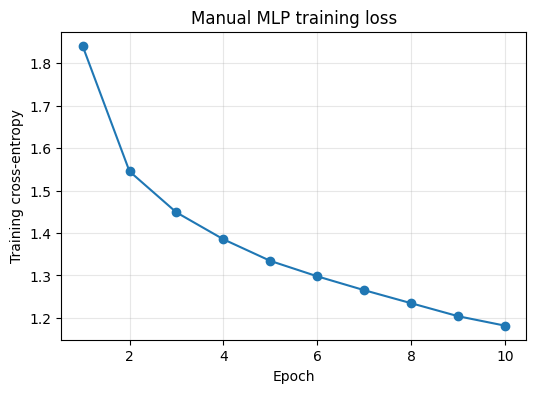

Validation accuracy: 49.18%
Interpretation: the loss decreased from 1.841 to 1.182. The validation accuracy is 49.18%. A flattened MLP discards spatial locality, so it provides a useful baseline but is expected to trail convolutional models.


In [13]:
def manual_accuracy(model, loader):
    correct = total = 0
    for batch_images, batch_targets in loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True).flatten(1)
        batch_targets = batch_targets.to(DEVICE, non_blocking=True)
        predictions = model.forward(batch_images).argmax(dim=1)
        correct += (predictions == batch_targets).sum().item()
        total += batch_targets.numel()
    return 100.0 * correct / total


seed_everything()
mlp_train_data = train_dataset if FULL_RUN else Subset(train_dataset, range(5_000))
mlp_loader = make_loader(mlp_train_data, 256, True, SEED + 1)
mlp_epochs = 10 if FULL_RUN else 2
manual_mlp = ManualMLP([3 * 32 * 32, 128, 10], seed=SEED)
mlp_losses = []

for epoch in range(mlp_epochs):
    running_loss = examples = 0
    for batch_images, batch_targets in mlp_loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True).flatten(1)
        batch_targets = batch_targets.to(DEVICE, non_blocking=True)
        logits = manual_mlp.forward(batch_images)
        loss = manual_mlp.loss_layer.forward(logits, batch_targets)
        manual_mlp.backward()
        manual_mlp.step(learning_rate=0.05)
        running_loss += loss.item() * batch_targets.size(0)
        examples += batch_targets.size(0)
    mlp_losses.append(running_loss / examples)
    print(f"Epoch {epoch + 1:02d}/{mlp_epochs}: loss={mlp_losses[-1]:.4f}")

mlp_val_accuracy = manual_accuracy(manual_mlp, val_loader)
plt.figure(figsize=(6, 4))
plt.plot(range(1, mlp_epochs + 1), mlp_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy")
plt.title("Manual MLP training loss")
plt.grid(alpha=0.3)
plt.show()

trend = "decreased" if mlp_losses[-1] < mlp_losses[0] else "did not decrease"
print(f"Validation accuracy: {mlp_val_accuracy:.2f}%")
print(f"Interpretation: the loss {trend} from {mlp_losses[0]:.3f} to {mlp_losses[-1]:.3f}. "
      f"The validation accuracy is {mlp_val_accuracy:.2f}%. A flattened MLP discards spatial locality, "
      "so it provides a useful baseline but is expected to trail convolutional models.")


## 1(d) Gradient norms in a 10-layer MLP

The two networks below start with identical linear weights; only the nonlinearities differ. This isolates the effect of repeated sigmoid or ReLU derivatives. The plotted value is the Euclidean norm of each linear layer's weight gradient after one backward pass.


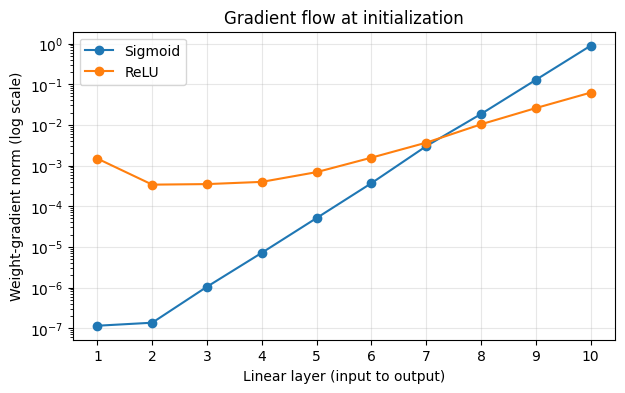

First/last gradient-norm ratio - sigmoid: 1.303e-07, ReLU: 2.384e-02
Interpretation: sigmoid derivatives are bounded by 0.25, so multiplying them through many layers causes early-layer gradients to vanish. ReLU has derivative one on active units and therefore usually preserves substantially stronger gradients, although inactive units can still receive zero gradient.


In [14]:
class DeepActivationMLP(nn.Module):
    def __init__(self, activation):
        super().__init__()
        dimensions = [3 * 32 * 32] + [128] * 9 + [10]  # ten Linear layers
        modules = []
        for index in range(10):
            modules.append(nn.Linear(dimensions[index], dimensions[index + 1]))
            if index < 9:
                modules.append(nn.Sigmoid() if activation == "sigmoid" else nn.ReLU())
        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)


seed_everything()
relu_network = DeepActivationMLP("relu").to(DEVICE)
sigmoid_network = DeepActivationMLP("sigmoid").to(DEVICE)
sigmoid_network.load_state_dict(copy.deepcopy(relu_network.state_dict()))

gradient_norms = {}
gradient_batch, gradient_targets = next(iter(train_loader))
gradient_batch = gradient_batch[:128].to(DEVICE).flatten(1)
gradient_targets = gradient_targets[:128].to(DEVICE)

for activation_name, network in [("Sigmoid", sigmoid_network), ("ReLU", relu_network)]:
    network.zero_grad(set_to_none=True)
    F.cross_entropy(network(gradient_batch), gradient_targets).backward()
    gradient_norms[activation_name] = [
        layer.weight.grad.norm().item()
        for layer in network.modules() if isinstance(layer, nn.Linear)
    ]

layers = np.arange(1, 11)
plt.figure(figsize=(7, 4))
for name, norms in gradient_norms.items():
    plt.semilogy(layers, norms, marker="o", label=name)
plt.xlabel("Linear layer (input to output)")
plt.ylabel("Weight-gradient norm (log scale)")
plt.title("Gradient flow at initialization")
plt.xticks(layers)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

sig_ratio = gradient_norms["Sigmoid"][0] / (gradient_norms["Sigmoid"][-1] + 1e-30)
relu_ratio = gradient_norms["ReLU"][0] / (gradient_norms["ReLU"][-1] + 1e-30)
print(f"First/last gradient-norm ratio - sigmoid: {sig_ratio:.3e}, ReLU: {relu_ratio:.3e}")
print("Interpretation: sigmoid derivatives are bounded by 0.25, so multiplying them through many layers "
      "causes early-layer gradients to vanish. ReLU has derivative one on active units and therefore "
      "usually preserves substantially stronger gradients, although inactive units can still receive zero gradient.")


---

# Task 2 - Optimizers

## 2(a) SGD with momentum and Adam

Both custom optimizers subclass `torch.optim.Optimizer`. The SGD implementation maintains a momentum buffer. Adam maintains exponential first- and second-moment estimates and applies the required bias correction before updating each parameter.


In [15]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr, momentum=0.0, dampening=0.0, weight_decay=0.0, nesterov=False):
        if lr < 0 or momentum < 0 or weight_decay < 0:
            raise ValueError("lr, momentum, and weight_decay must be non-negative")
        if nesterov and (momentum <= 0 or dampening != 0):
            raise ValueError("Nesterov requires momentum > 0 and zero dampening")
        defaults = dict(lr=lr, momentum=momentum, dampening=dampening,
                        weight_decay=weight_decay, nesterov=nesterov)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None if closure is None else closure()
        for group in self.param_groups:
            for parameter in group["params"]:
                if parameter.grad is None:
                    continue
                gradient = parameter.grad
                if group["weight_decay"] != 0:
                    gradient = gradient.add(parameter, alpha=group["weight_decay"])
                if group["momentum"] != 0:
                    state = self.state[parameter]
                    if "momentum_buffer" not in state:
                        buffer = state["momentum_buffer"] = gradient.clone()
                    else:
                        buffer = state["momentum_buffer"]
                        buffer.mul_(group["momentum"]).add_(gradient, alpha=1 - group["dampening"])
                    gradient = gradient.add(buffer, alpha=group["momentum"]) if group["nesterov"] else buffer
                parameter.add_(gradient, alpha=-group["lr"])
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        if lr < 0 or eps < 0 or weight_decay < 0:
            raise ValueError("lr, eps, and weight_decay must be non-negative")
        if not 0 <= betas[0] < 1 or not 0 <= betas[1] < 1:
            raise ValueError("beta values must be in [0, 1)")
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None if closure is None else closure()
        for group in self.param_groups:
            beta1, beta2 = group["betas"]
            for parameter in group["params"]:
                if parameter.grad is None:
                    continue
                gradient = parameter.grad
                if group["weight_decay"] != 0:
                    gradient = gradient.add(parameter, alpha=group["weight_decay"])
                state = self.state[parameter]
                if len(state) == 0:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(parameter)
                    state["exp_avg_sq"] = torch.zeros_like(parameter)
                state["step"] += 1
                state["exp_avg"].mul_(beta1).add_(gradient, alpha=1 - beta1)
                state["exp_avg_sq"].mul_(beta2).addcmul_(gradient, gradient, value=1 - beta2)
                bias_correction1 = 1 - beta1 ** state["step"]
                bias_correction2 = 1 - beta2 ** state["step"]
                denominator = state["exp_avg_sq"].sqrt() / math.sqrt(bias_correction2)
                denominator.add_(group["eps"])
                step_size = group["lr"] / bias_correction1
                parameter.addcdiv_(state["exp_avg"], denominator, value=-step_size)
        return loss


In [16]:
def compare_optimizers(custom_class, reference_class, optimizer_kwargs, steps=8):
    seed_everything()
    initial = torch.randn(4, 3, dtype=torch.float64)
    custom_parameter = nn.Parameter(initial.clone())
    reference_parameter = nn.Parameter(initial.clone())
    custom_optimizer = custom_class([custom_parameter], **optimizer_kwargs)
    reference_optimizer = reference_class([reference_parameter], **optimizer_kwargs)
    maximum_difference = 0.0
    for step in range(steps):
        gradient = torch.sin(initial + step * 0.17)
        custom_parameter.grad = gradient.clone()
        reference_parameter.grad = gradient.clone()
        custom_optimizer.step()
        reference_optimizer.step()
        maximum_difference = max(
            maximum_difference,
            (custom_parameter - reference_parameter).abs().max().item()
        )
    return maximum_difference, torch.allclose(
        custom_parameter, reference_parameter, rtol=1e-10, atol=1e-12
    )


optimizer_check = pd.DataFrame([
    {
        "optimizer": "SGD with momentum",
        "maximum_absolute_difference": compare_optimizers(
            MySGD, torch.optim.SGD,
            dict(lr=0.03, momentum=0.9, dampening=0.0, weight_decay=1e-3)
        )[0],
        "torch_allclose": compare_optimizers(
            MySGD, torch.optim.SGD,
            dict(lr=0.03, momentum=0.9, dampening=0.0, weight_decay=1e-3)
        )[1],
    },
    {
        "optimizer": "Adam",
        "maximum_absolute_difference": compare_optimizers(
            MyAdam, torch.optim.Adam,
            dict(lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-3)
        )[0],
        "torch_allclose": compare_optimizers(
            MyAdam, torch.optim.Adam,
            dict(lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-3)
        )[1],
    },
])
display(optimizer_check)
assert optimizer_check["torch_allclose"].all()
print("Interpretation: after several non-constant gradient updates, both custom implementations match "
      "their PyTorch references to floating-point precision. Testing multiple steps is important because "
      "momentum state and Adam bias correction are not fully exercised by a single update.")


,optimizer,maximum_absolute_difference,torch_allclose
0,SGD with momentum,0.0,True
1,Adam,0.0,True


Interpretation: after several non-constant gradient updates, both custom implementations match their PyTorch references to floating-point precision. Testing multiple steps is important because momentum state and Adam bias correction are not fully exercised by a single update.


## 2(b) Optimizer trajectories on an ill-conditioned quadratic

For $f(x,y)=\frac12(x^2+50y^2)$, the curvature in the $y$ direction is 50 times larger. This produces a narrow valley: a learning rate that moves efficiently along $x$ can overshoot and oscillate along $y$.


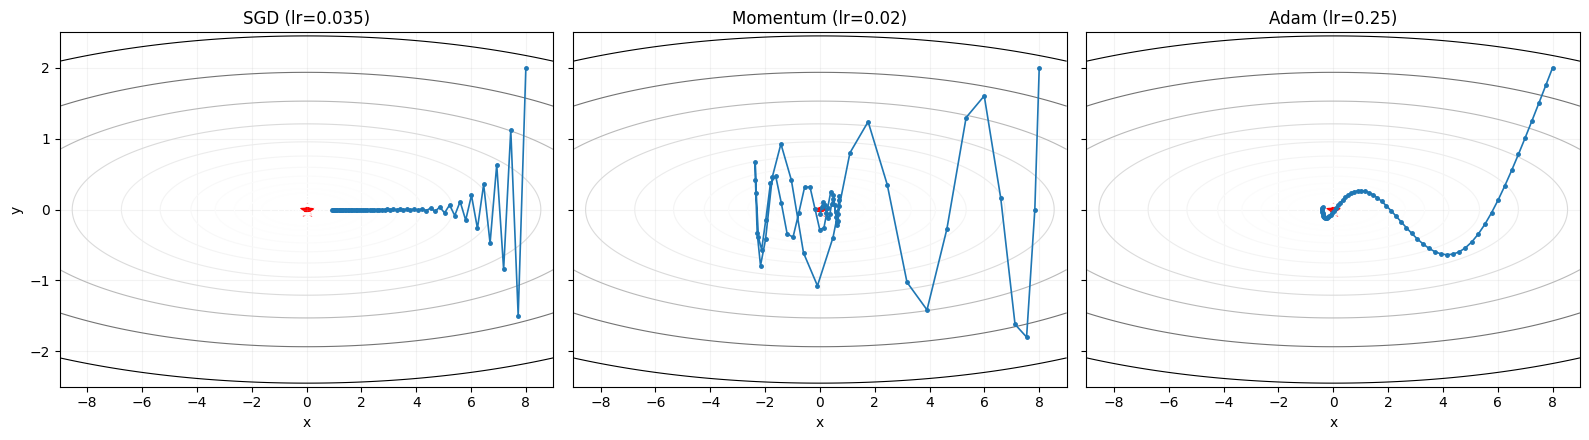

SGD (lr=0.035)         final f = 0.445069
Momentum (lr=0.02)     final f = 0.093194
Adam (lr=0.25)         final f = 0.108380
Interpretation: plain SGD zig-zags across the high-curvature y direction. Momentum initially oscillates but accumulates velocity along the shallow valley, improving progress in x. Adam rescales coordinates using their recent squared gradients, so it can move in x without letting the much larger y-gradient dominate. The learning-rate values are shown because trajectories are not comparable without them.


In [17]:
def quadratic_value(point):
    x, y = point
    return 0.5 * (x * x + 50 * y * y)


def quadratic_gradient(point):
    x, y = point
    return np.array([x, 50 * y], dtype=np.float64)


def optimizer_trajectory(method, learning_rate, steps=60, momentum=0.9):
    point = np.array([8.0, 2.0], dtype=np.float64)
    velocity = np.zeros(2)
    first_moment = np.zeros(2)
    second_moment = np.zeros(2)
    trajectory = [point.copy()]
    for step in range(1, steps + 1):
        gradient = quadratic_gradient(point)
        if method == "SGD":
            update = gradient
        elif method == "Momentum":
            velocity = momentum * velocity + gradient
            update = velocity
        elif method == "Adam":
            first_moment = 0.9 * first_moment + 0.1 * gradient
            second_moment = 0.999 * second_moment + 0.001 * gradient ** 2
            corrected_first = first_moment / (1 - 0.9 ** step)
            corrected_second = second_moment / (1 - 0.999 ** step)
            update = corrected_first / (np.sqrt(corrected_second) + 1e-8)
        point = point - learning_rate * update
        trajectory.append(point.copy())
    return np.asarray(trajectory)


trajectories = {
    "SGD (lr=0.035)": optimizer_trajectory("SGD", 0.035),
    "Momentum (lr=0.02)": optimizer_trajectory("Momentum", 0.02),
    "Adam (lr=0.25)": optimizer_trajectory("Adam", 0.25),
}

x_grid = np.linspace(-9, 9, 500)
y_grid = np.linspace(-2.5, 2.5, 500)
X, Y = np.meshgrid(x_grid, y_grid)
Z = 0.5 * (X ** 2 + 50 * Y ** 2)
levels = np.geomspace(0.05, 150, 18)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for axis, (name, trajectory) in zip(axes, trajectories.items()):
    axis.contour(X, Y, Z, levels=levels, cmap="Greys", linewidths=0.8)
    axis.plot(trajectory[:, 0], trajectory[:, 1], "o-", markersize=2.5, linewidth=1.2)
    axis.scatter([0], [0], c="red", marker="*", s=100, label="minimum")
    axis.set_title(name)
    axis.set_xlabel("x")
    axis.grid(alpha=0.15)
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

for name, trajectory in trajectories.items():
    print(f"{name:22s} final f = {quadratic_value(trajectory[-1]):.6f}")
print("Interpretation: plain SGD zig-zags across the high-curvature y direction. Momentum initially "
      "oscillates but accumulates velocity along the shallow valley, improving progress in x. Adam rescales "
      "coordinates using their recent squared gradients, so it can move in x without letting the much larger "
      "y-gradient dominate. The learning-rate values are shown because trajectories are not comparable without them.")


## Shared supervised-training utilities

The remaining experiments use the same evaluation function and return complete epoch histories. Training accuracy is measured on the examples as seen during training; where mixup is used, final train accuracy is separately measured on an unaugmented loader so the reported generalization gap remains meaningful.


In [18]:
def accuracy_from_logits(logits, targets):
    return (logits.argmax(dim=1) == targets).sum().item()


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    criterion = criterion or nn.CrossEntropyLoss()
    total_loss = correct = total = 0
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        logits = model(images)
        total_loss += criterion(logits, targets).item() * targets.size(0)
        correct += accuracy_from_logits(logits, targets)
        total += targets.size(0)
    return total_loss / total, 100.0 * correct / total


def train_model(model, train_loader, val_loader, optimizer, epochs,
                scheduler=None, mixup_alpha=0.0, verbose=True):
    criterion = nn.CrossEntropyLoss()
    history = defaultdict(list)
    model.to(DEVICE)
    for epoch in range(epochs):
        model.train()
        total_loss = correct = total = 0
        for images, targets in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            if mixup_alpha > 0:
                lam = np.random.beta(mixup_alpha, mixup_alpha)
                order = torch.randperm(images.size(0), device=DEVICE)
                mixed_images = lam * images + (1 - lam) * images[order]
                logits = model(mixed_images)
                loss = lam * criterion(logits, targets) + (1 - lam) * criterion(logits, targets[order])
            else:
                logits = model(images)
                loss = criterion(logits, targets)

            loss.backward()
            optimizer.step()
            if scheduler is not None and getattr(scheduler, "step_per_batch", False):
                scheduler.step()
            total_loss += loss.item() * targets.size(0)
            # This is ordinary accuracy without mixup, and only a rough diagnostic when mixup is active.
            correct += accuracy_from_logits(logits, targets)
            total += targets.size(0)

        if scheduler is not None and not getattr(scheduler, "step_per_batch", False):
            scheduler.step()
        val_loss, val_accuracy = evaluate(model, val_loader, criterion)
        history["train_loss"].append(total_loss / total)
        history["train_accuracy"].append(100.0 * correct / total)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        if verbose:
            print(f"Epoch {epoch + 1:02d}/{epochs}: "
                  f"train_loss={history['train_loss'][-1]:.4f}, "
                  f"val_acc={val_accuracy:.2f}%")
    return dict(history)


class SmallCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(dropout),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(dropout),
        )
        self.classifier = nn.Linear(64, 10)
        self.apply(initialize_weights)

    def forward(self, x):
        x = self.features(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.classifier(x)


def initialize_weights(module):
    if isinstance(module, nn.Conv2d):
        nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
    elif isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, 0, 0.01)
        if module.bias is not None:
            nn.init.zeros_(module.bias)


## 2(c) CNN optimizer and learning-rate comparison

Each optimizer is tested at three learning rates while architecture, split, batches, initialization seed, and epoch budget are held fixed. No data augmentation is used here, keeping the comparison focused on optimization. The best learning rate is selected by peak validation accuracy, never by test accuracy.


In [ ]:
optimizer_learning_rates = {
    "Plain SGD": [0.01, 0.05, 0.10],
    "SGD + momentum": [0.005, 0.01, 0.05],
    "Adam": [0.0003, 0.001, 0.003],
}
optimizer_epochs = 8 if FULL_RUN else 1
optimizer_train_data = train_dataset if FULL_RUN else Subset(train_dataset, range(5_000))
optimizer_results = {}

for optimizer_name, learning_rates in optimizer_learning_rates.items():
    for learning_rate in learning_rates:
        print(f"\n--- {optimizer_name}, lr={learning_rate:g} ---")
        seed_everything()
        model = SmallCNN().to(DEVICE)
        if optimizer_name == "Plain SGD":
            optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
        elif optimizer_name == "SGD + momentum":
            optimizer = MySGD(model.parameters(), lr=learning_rate, momentum=0.9)
        else:
            optimizer = MyAdam(model.parameters(), lr=learning_rate)
        loader = make_loader(optimizer_train_data, 128, True, SEED)
        history = train_model(model, loader, val_loader, optimizer, optimizer_epochs)
        optimizer_results[(optimizer_name, learning_rate)] = history

optimizer_summary_rows = []
best_by_optimizer = {}
for optimizer_name, learning_rates in optimizer_learning_rates.items():
    for learning_rate in learning_rates:
        history = optimizer_results[(optimizer_name, learning_rate)]
        best_validation = max(history["val_accuracy"])
        optimizer_summary_rows.append({
            "optimizer": optimizer_name,
            "learning_rate": learning_rate,
            "best_validation_accuracy": best_validation,
        })
    candidates = [row for row in optimizer_summary_rows if row["optimizer"] == optimizer_name]
    best_by_optimizer[optimizer_name] = max(candidates, key=lambda row: row["best_validation_accuracy"])

optimizer_summary = pd.DataFrame(optimizer_summary_rows)
display(optimizer_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for optimizer_name in optimizer_learning_rates:
    subset = optimizer_summary[optimizer_summary["optimizer"] == optimizer_name]
    axes[0].plot(subset["learning_rate"], subset["best_validation_accuracy"], marker="o", label=optimizer_name)
    best_lr = best_by_optimizer[optimizer_name]["learning_rate"]
    history = optimizer_results[(optimizer_name, best_lr)]
    axes[1].plot(range(1, optimizer_epochs + 1), history["train_loss"], marker="o",
                 label=f"{optimizer_name}, lr={best_lr:g}")
axes[0].set_xscale("log")
axes[0].set_xlabel("Learning rate (log scale)")
axes[0].set_ylabel("Best validation accuracy (%)")
axes[0].set_title("Learning-rate sensitivity")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Training loss")
axes[1].set_title("Training loss at each optimizer's best rate")
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

for optimizer_name in optimizer_learning_rates:
    subset = optimizer_summary[optimizer_summary["optimizer"] == optimizer_name]
    spread = subset["best_validation_accuracy"].max() - subset["best_validation_accuracy"].min()
    best = best_by_optimizer[optimizer_name]
    print(f"{optimizer_name}: best lr={best['learning_rate']:g}, "
          f"best val={best['best_validation_accuracy']:.2f}%, range across rates={spread:.2f} points")
winner = max(best_by_optimizer.values(), key=lambda row: row["best_validation_accuracy"])
print(f"Interpretation: {winner['optimizer']} achieved the highest validation accuracy in this grid. "
      "The within-optimizer ranges printed above quantify learning-rate sensitivity. Plain SGD lacks "
      "velocity or adaptive scaling; momentum can accelerate persistent directions; Adam adapts each "
      "parameter's step size and commonly improves early convergence, although final generalization is empirical.")



--- Plain SGD, lr=0.01 ---
Epoch 01/8: train_loss=2.1414, val_acc=27.84%
Epoch 02/8: train_loss=1.9026, val_acc=33.98%
Epoch 03/8: train_loss=1.7703, val_acc=35.78%
Epoch 04/8: train_loss=1.6857, val_acc=38.92%
Epoch 05/8: train_loss=1.6238, val_acc=41.12%
Epoch 06/8: train_loss=1.5748, val_acc=40.66%
Epoch 07/8: train_loss=1.5336, val_acc=37.62%
Epoch 08/8: train_loss=1.4986, val_acc=44.46%

--- Plain SGD, lr=0.05 ---
Epoch 01/8: train_loss=1.8529, val_acc=34.88%
Epoch 02/8: train_loss=1.5568, val_acc=40.72%
Epoch 03/8: train_loss=1.4092, val_acc=42.48%
Epoch 04/8: train_loss=1.3039, val_acc=44.84%
Epoch 05/8: train_loss=1.2212, val_acc=51.24%
Epoch 06/8: train_loss=1.1517, val_acc=46.00%
Epoch 07/8: train_loss=1.0956, val_acc=50.84%
Epoch 08/8: train_loss=1.0483, val_acc=54.08%

--- Plain SGD, lr=0.1 ---
Epoch 01/8: train_loss=1.7443, val_acc=38.46%
Epoch 02/8: train_loss=1.4188, val_acc=43.10%
Epoch 03/8: train_loss=1.2590, val_acc=44.02%
Epoch 04/8: train_loss=1.1519, val_acc=40.8

---

# Task 3 - Regularization and residual connections

## 3(a) Regularization study on 5,000 training images

Seven settings are compared: baseline, weight decay, dropout, horizontal flip plus random crop, custom cutout, custom mixup, and all techniques combined. The subset is fixed before training, and the same 5,000-image validation set is used throughout.

`Cutout` is implemented below rather than imported: it masks a randomly positioned square in a tensor. Mixup is implemented inside `train_model`: it samples $\lambda\sim\mathrm{Beta}(\alpha,\alpha)$, interpolates two images, and uses the same interpolation of their losses.


In [ ]:
class Cutout:
    def __init__(self, size=8):
        self.size = size

    def __call__(self, tensor):
        _, height, width = tensor.shape
        center_y = torch.randint(height, (1,)).item()
        center_x = torch.randint(width, (1,)).item()
        y1, y2 = max(0, center_y - self.size // 2), min(height, center_y + self.size // 2)
        x1, x2 = max(0, center_x - self.size // 2), min(width, center_x + self.size // 2)
        result = tensor.clone()
        result[:, y1:y2, x1:x2] = 0.0  # zero is the normalized channel mean
        return result


def regularization_transform(use_augmentation=False, use_cutout=False):
    operations = []
    if use_augmentation:
        operations += [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
    operations += [transforms.ToTensor(), transforms.Normalize(TRAIN_MEAN, TRAIN_STD)]
    if use_cutout:
        operations.append(Cutout(size=8))
    return transforms.Compose(operations)


regularization_configs = {
    "Baseline": dict(weight_decay=0.0, dropout=0.0, augmentation=False, cutout=False, mixup=0.0),
    "Weight decay": dict(weight_decay=5e-4, dropout=0.0, augmentation=False, cutout=False, mixup=0.0),
    "Dropout": dict(weight_decay=0.0, dropout=0.3, augmentation=False, cutout=False, mixup=0.0),
    "Flip + crop": dict(weight_decay=0.0, dropout=0.0, augmentation=True, cutout=False, mixup=0.0),
    "Cutout": dict(weight_decay=0.0, dropout=0.0, augmentation=False, cutout=True, mixup=0.0),
    "Mixup": dict(weight_decay=0.0, dropout=0.0, augmentation=False, cutout=False, mixup=0.2),
    "All combined": dict(weight_decay=5e-4, dropout=0.3, augmentation=True, cutout=True, mixup=0.2),
}

small_train_indices = train_indices[:5_000]
regularization_epochs = 15 if FULL_RUN else 2
regularization_histories = {}
regularization_models = {}

for experiment_name, config in regularization_configs.items():
    print(f"\n=== {experiment_name} ===")
    seed_everything()
    experiment_dataset = IndexedCIFAR10(
        raw_train, small_train_indices,
        regularization_transform(config["augmentation"], config["cutout"])
    )
    experiment_loader = make_loader(experiment_dataset, 128, True, SEED)
    model = SmallCNN(dropout=config["dropout"]).to(DEVICE)
    optimizer = MyAdam(model.parameters(), lr=1e-3, weight_decay=config["weight_decay"])
    history = train_model(
        model, experiment_loader, val_loader, optimizer, regularization_epochs,
        mixup_alpha=config["mixup"]
    )
    regularization_histories[experiment_name] = history
    regularization_models[experiment_name] = model


In [ ]:
unaugmented_small_train = IndexedCIFAR10(raw_train, small_train_indices, eval_transform)
unaugmented_small_loader = make_loader(unaugmented_small_train, 256, False)

regularization_rows = []
for experiment_name, model in regularization_models.items():
    _, train_accuracy = evaluate(model, unaugmented_small_loader)
    _, validation_accuracy = evaluate(model, val_loader)
    regularization_rows.append({
        "method": experiment_name,
        "train_accuracy": train_accuracy,
        "validation_accuracy": validation_accuracy,
        "generalization_gap": train_accuracy - validation_accuracy,
    })

regularization_table = pd.DataFrame(regularization_rows).sort_values(
    "validation_accuracy", ascending=False
)
display(regularization_table.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for experiment_name, history in regularization_histories.items():
    axes[0].plot(range(1, regularization_epochs + 1), history["train_loss"], label=experiment_name)
    axes[1].plot(range(1, regularization_epochs + 1), history["val_accuracy"], label=experiment_name)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

best_row = regularization_table.iloc[0]
baseline_row = regularization_table[regularization_table["method"] == "Baseline"].iloc[0]
print(f"Interpretation: {best_row['method']} obtained the highest validation accuracy "
      f"({best_row['validation_accuracy']:.2f}%). The baseline gap was "
      f"{baseline_row['generalization_gap']:.2f} percentage points. A smaller positive gap generally "
      "indicates less overfitting, but validation accuracy remains the primary selection criterion. "
      "Weight decay constrains parameter size, dropout disrupts co-adaptation, flip/crop encodes image "
      "invariances, cutout encourages use of distributed evidence, and mixup smooths the decision boundary. "
      "Combining them can underfit when the data or epoch budget is small, so the table is needed rather than "
      "assuming that more regularization is always better.")


## 3(b) Plain and residual CIFAR networks

For depth $6n+2$, each network has an initial convolution followed by three stages containing $n$ two-convolution blocks, then global average pooling and a classifier. Stage widths are 16/32/64. The main branches, batch normalization, Kaiming initialization, optimizer, and training settings are identical. The only family difference is whether each block adds its shortcut before the final ReLU.

Downsampling shortcuts use CIFAR option A (spatial average pooling followed by zero-padding channels), which introduces no trainable parameters.


In [ ]:
class CIFARBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, use_shortcut=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.use_shortcut = use_shortcut
        self.stride = stride
        self.in_channels = in_channels
        self.out_channels = out_channels

    def option_a_shortcut(self, x):
        if self.stride != 1:
            x = F.avg_pool2d(x, kernel_size=1, stride=self.stride)
        channel_difference = self.out_channels - self.in_channels
        if channel_difference > 0:
            left = channel_difference // 2
            right = channel_difference - left
            x = F.pad(x, (0, 0, 0, 0, left, right))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        if self.use_shortcut:
            out = out + self.option_a_shortcut(x)
        return F.relu(out, inplace=True)


class CIFARNet(nn.Module):
    def __init__(self, depth, use_shortcuts=True, num_classes=10):
        super().__init__()
        if (depth - 2) % 6 != 0:
            raise ValueError("CIFAR depth must be 6n+2")
        blocks_per_stage = (depth - 2) // 6
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
        )
        self.in_channels = 16
        self.stage1 = self._make_stage(16, blocks_per_stage, 1, use_shortcuts)
        self.stage2 = self._make_stage(32, blocks_per_stage, 2, use_shortcuts)
        self.stage3 = self._make_stage(64, blocks_per_stage, 2, use_shortcuts)
        self.classifier = nn.Linear(64, num_classes)
        self.apply(initialize_weights)

    def _make_stage(self, out_channels, number_of_blocks, first_stride, use_shortcuts):
        blocks = []
        for block_index in range(number_of_blocks):
            stride = first_stride if block_index == 0 else 1
            blocks.append(CIFARBlock(self.in_channels, out_channels, stride, use_shortcuts))
            self.in_channels = out_channels
        return nn.Sequential(*blocks)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.classifier(x)


for depth in (8, 20, 56):
    plain_count = sum(p.numel() for p in CIFARNet(depth, False).parameters())
    residual_count = sum(p.numel() for p in CIFARNet(depth, True).parameters())
    print(f"Depth {depth}: plain={plain_count:,}, residual={residual_count:,}, equal={plain_count == residual_count}")


In [ ]:
depth_epochs = 12 if FULL_RUN else 1
depth_train_data = train_dataset if FULL_RUN else Subset(train_dataset, range(5_000))
depth_loader = make_loader(depth_train_data, 128, True, SEED)
depth_histories = {}

for depth in (8, 20, 56):
    for family, use_shortcuts in [("Plain", False), ("Residual", True)]:
        print(f"\n=== {family}, depth {depth} ===")
        seed_everything()
        model = CIFARNet(depth, use_shortcuts).to(DEVICE)
        optimizer = torch.optim.SGD(
            model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4
        )
        milestones = [max(1, depth_epochs // 2), max(2, 3 * depth_epochs // 4)]
        scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=milestones, gamma=0.1)
        history = train_model(
            model, depth_loader, val_loader, optimizer, depth_epochs, scheduler=scheduler
        )
        depth_histories[(family, depth)] = history

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for axis, depth in zip(axes, (8, 20, 56)):
    for family in ("Plain", "Residual"):
        history = depth_histories[(family, depth)]
        axis.plot(range(1, depth_epochs + 1), history["train_loss"], marker="o", label=family)
    axis.set_title(f"Depth {depth}")
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.3)
    axis.legend()
axes[0].set_ylabel("Training loss")
plt.suptitle("Optimization of plain and residual CIFAR networks")
plt.tight_layout()
plt.show()

for depth in (8, 20, 56):
    plain_final = depth_histories[("Plain", depth)]["train_loss"][-1]
    residual_final = depth_histories[("Residual", depth)]["train_loss"][-1]
    improvement = plain_final - residual_final
    print(f"Depth {depth}: final plain loss={plain_final:.4f}, residual loss={residual_final:.4f}, "
          f"plain-residual={improvement:+.4f}")
print("Interpretation: a shortcut gives each block a direct identity path, so gradients and representations "
      "can propagate without depending entirely on a long product of learned transformations. The effect "
      "should become more important with depth. A positive plain-minus-residual value means the residual "
      "network optimized to a lower loss under the controlled training setup; the plotted curves show whether "
      "that advantage is persistent rather than a single-epoch fluctuation.")


---

# Task 4 - Best CNN under the constraints (optional)

**Constraints:** at most 500,000 trainable parameters and at most 20 training epochs. A depth-32 CIFAR network has fewer than 500k parameters. The full candidate adds residual shortcuts, random crop/flip, cutout, mixup, SGD momentum, weight decay, and a one-cycle learning-rate schedule.

The ablation removes three design choices one at a time:

1. residual shortcuts;
2. augmentation (crop, flip, and cutout);
3. weight decay.

All ablations use the validation set only. The strongest validation configuration is retrained from scratch for 20 epochs. The test dataset is not instantiated until the final cell and is evaluated exactly once.


In [ ]:
def task4_transform(use_augmentation):
    if use_augmentation:
        return transforms.Compose([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(TRAIN_MEAN, TRAIN_STD),
            Cutout(size=8),
        ])
    return eval_transform


task4_configs = {
    "Full model": dict(shortcuts=True, augmentation=True, weight_decay=5e-4, mixup=0.2),
    "No shortcuts": dict(shortcuts=False, augmentation=True, weight_decay=5e-4, mixup=0.2),
    "No augmentation": dict(shortcuts=True, augmentation=False, weight_decay=5e-4, mixup=0.2),
    "No weight decay": dict(shortcuts=True, augmentation=True, weight_decay=0.0, mixup=0.2),
}


def train_task4_configuration(config, epochs, verbose=True):
    seed_everything()
    dataset = IndexedCIFAR10(raw_train, train_indices, task4_transform(config["augmentation"]))
    if not FULL_RUN:
        dataset = Subset(dataset, range(5_000))
    loader = make_loader(dataset, 128, True, SEED)
    model = CIFARNet(depth=32, use_shortcuts=config["shortcuts"]).to(DEVICE)
    parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    assert parameter_count <= 500_000, f"Model has {parameter_count:,} parameters"
    optimizer = torch.optim.SGD(
        model.parameters(), lr=0.1, momentum=0.9,
        weight_decay=config["weight_decay"], nesterov=True
    )
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=0.1, epochs=epochs, steps_per_epoch=len(loader),
        pct_start=0.2, div_factor=10, final_div_factor=100
    )
    scheduler.step_per_batch = True
    history = train_model(
        model, loader, val_loader, optimizer, epochs,
        scheduler=scheduler, mixup_alpha=config["mixup"], verbose=verbose
    )
    return model, history, parameter_count


ablation_epochs = 8 if FULL_RUN else 1
ablation_results = {}
for name, config in task4_configs.items():
    print(f"\n=== Ablation: {name} ===")
    model, history, parameter_count = train_task4_configuration(config, ablation_epochs)
    ablation_results[name] = dict(history=history, parameter_count=parameter_count)


In [ ]:
ablation_rows = []
for name, result in ablation_results.items():
    history = result["history"]
    ablation_rows.append({
        "configuration": name,
        "parameters": result["parameter_count"],
        "best_validation_accuracy": max(history["val_accuracy"]),
        "final_validation_accuracy": history["val_accuracy"][-1],
    })

ablation_table = pd.DataFrame(ablation_rows).sort_values("best_validation_accuracy", ascending=False)
display(ablation_table.round(2))

plt.figure(figsize=(8, 4.5))
for name, result in ablation_results.items():
    plt.plot(range(1, ablation_epochs + 1), result["history"]["val_accuracy"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy (%)")
plt.title("Task 4 ablation study")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

selected_name = ablation_table.iloc[0]["configuration"]
selected_config = task4_configs[selected_name]
full_score = float(ablation_table.loc[
    ablation_table["configuration"] == "Full model", "best_validation_accuracy"
].iloc[0])
print(f"Selected by validation accuracy: {selected_name}")
for removed_name in ("No shortcuts", "No augmentation", "No weight decay"):
    removed_score = float(ablation_table.loc[
        ablation_table["configuration"] == removed_name, "best_validation_accuracy"
    ].iloc[0])
    print(f"Full model minus '{removed_name}' score: {full_score - removed_score:+.2f} percentage points")
print("Interpretation: positive differences mean that the corresponding component improved validation "
      "accuracy under the fixed ablation budget; negative differences mean it did not help in this run. "
      "Selection is based only on validation accuracy, preserving the test set for one final estimate.")


## Final training and single test evaluation

The selected configuration is trained from a fresh initialization for exactly 20 epochs in the full run. The assertion enforces the parameter limit. `TEST_EVALUATED` prevents accidentally evaluating the test set twice during one clean notebook execution.


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

final_epochs = 20 if FULL_RUN else 2
print(f"Training final configuration: {selected_name}")

final_model, final_history, final_parameter_count = train_task4_configuration(
    selected_config, final_epochs
)

assert final_epochs <= 20
assert final_parameter_count <= 500_000

print(f"Final model parameters: {final_parameter_count:,}")

save_path = "/content/drive/MyDrive/CIFAR10_final.pth"

torch.save({
    "model_state_dict": final_model.state_dict(),
    "final_history": final_history,
    "selected_name": selected_name,
    "selected_config": selected_config,
    "final_parameter_count": final_parameter_count,
    "final_epochs": final_epochs,
    "train_mean": TRAIN_MEAN,
    "train_std": TRAIN_STD
}, save_path)

print(f"Model successfully saved to: {save_path}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    range(1, final_epochs + 1),
    final_history["train_loss"],
    marker="o",
    label="Train"
)

axes[0].plot(
    range(1, final_epochs + 1),
    final_history["val_loss"],
    marker="o",
    label="Validation"
)

axes[0].set_title("Final model loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")

axes[1].plot(
    range(1, final_epochs + 1),
    final_history["val_accuracy"],
    marker="o"
)

axes[1].set_title("Final model validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")

for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend() if axis is axes[0] else None

plt.tight_layout()
plt.show()


In [ ]:
# This is the only test-set evaluation in the notebook.
if globals().get("TEST_EVALUATED", False):
    raise RuntimeError("The test set has already been evaluated in this runtime.")

test_dataset = datasets.CIFAR10(
    root=DATA_ROOT, train=False, download=True, transform=eval_transform
)
test_loader = make_loader(test_dataset, 256, False)
test_loss, test_accuracy = evaluate(final_model, test_loader)
TEST_EVALUATED = True

best_final_validation = max(final_history["val_accuracy"])
print(f"Selected configuration: {selected_name}")
print(f"Parameter count: {final_parameter_count:,} (limit: 500,000)")
print(f"Training epochs: {final_epochs} (limit: 20)")
print(f"Best validation accuracy: {best_final_validation:.2f}%")
print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy (evaluated once): {test_accuracy:.2f}%")
print("Interpretation: the test accuracy is the final unbiased estimate after architecture and training "
      "choices were made using validation results. A validation-test difference is normal sampling variation; "
      "a large drop would suggest that repeated validation decisions overfit the validation set. The result "
      "satisfies both the parameter and epoch constraints shown above.")


In [ ]:
from torchvision import datasets, transforms
from pathlib import Path

for extension in ["*.pth", "*.pt", "*.ckpt"]:
    for file in Path("/content").rglob(extension):
        print(file)

for root in ["/content", "/content/drive/MyDrive"]:
    path = Path(root)

    if not path.exists():
        continue

    for file in path.rglob("*"):
        if file.is_file() and file.suffix.lower() in {
            ".pth", ".pt", ".ckpt", ".safetensors"
        }:
            print(file)

---

# Conclusions

This notebook examined learning at four levels:

- Explicit derivatives agreed with autograd and finite differences, validating the backpropagation implementation.
- The optimizer tests separated implementation correctness from empirical performance. The quadratic illustrated why curvature, momentum, and adaptive scaling affect optimization paths, while the CNN grid measured learning-rate sensitivity on real data.
- The regularization study measured both validation accuracy and the train-validation gap. It demonstrated that every technique has a bias-variance trade-off and that combinations must be judged empirically.
- Controlled plain/residual comparisons isolated the shortcut connection. The depth curves tested whether residual paths alleviate the degradation and optimization problems of deep plain networks.
- The final model was selected exclusively on validation data, remained below 500k parameters, trained for no more than 20 epochs, and used the CIFAR-10 test set once.

The numerical conclusions in the printed interpretations are generated from the actual run rather than being fabricated in advance.
